# High-Risk Pregnancy Detection with Random Forest

**Goal.** Flag high-risk pregnancies from six routine vitals that a rural health centre can measure, so referral and emergency transport can start earlier.

**Dataset.** [Maternal Health Risk (UCI #863)](https://archive.ics.uci.edu/dataset/863/maternal+health+risk), Ahmed 2020, CC BY 4.0. Collected at hospitals and community clinics in rural Bangladesh. Features: `Age`, `SystolicBP`, `DiastolicBP`, `BS` (blood sugar, mmol/L), `BodyTemp` (°F), `HeartRate`. Target: `RiskLevel` (Low / Mid / High).

**What this notebook does**

| Step | Section |
|---|---|
| 1 | Setup and configuration |
| 2 | Load data (UCI first, GitHub copy as fallback) |
| 3 | Data audit: missing values, ranges, duplicates, class balance |
| 4 | Cleaning |
| 5 | Exploratory plots |
| 6 | Why duplicates must be removed before splitting (leakage demo) |
| 7 | Train/test split |
| 8 | Baselines and Random Forest tuning |
| 9 | Held-out test evaluation |
| 10 | Repeated cross-validation model comparison |
| 11 | Feature importance |
| 12 | Alert threshold analysis for the High-risk class |
| 13 | Save the model and a safe inference helper |
| 14 | Limitations and next steps |

**How to run in Colab.** Upload this file to Colab (File > Upload notebook) and choose *Runtime > Run all*. No GPU is needed. Runtime is a few minutes, mostly the hyperparameter search.

> **Safety note.** This is a research prototype and a screening aid. It is not a diagnostic tool and must not replace clinical judgement or danger-sign protocols.

## 1. Setup and configuration

In [1]:
# ucimlrepo is only needed to download the original UCI file; it is preinstalled nowhere by default.
!pip -q install ucimlrepo

import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     RandomizedSearchCV, cross_validate)
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_score, confusion_matrix,
                             classification_report, roc_curve, auc, precision_recall_curve,
                             average_precision_score, make_scorer)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# ---- Configuration (edit here) -------------------------------------------------------------
SEED = 42                      # one seed for every random step, for reproducibility
DATA_SOURCE = os.environ.get("DATA_SOURCE", "auto")   # "auto" | "uci" | "github_copy"
GITHUB_COPY_URL = ("https://raw.githubusercontent.com/a-leena/maternal_health_risk/main/"
                   "data/all_features_data.csv")      # community copy (935 rows), fallback only
TEST_SIZE = 0.20
N_SEARCH_ITER = 40             # random hyperparameter configurations to try
ALERT_THRESHOLD = 0.20         # starting High-risk alert threshold (see section 12)
MIN_PLAUSIBLE_HR = 40          # bpm; rows below this are treated as data-entry errors

FEATURES = ["Age", "SystolicBP", "DiastolicBP", "BS", "BodyTemp", "HeartRate"]
CLASSES = ["Low", "Mid", "High"]           # encoded 0, 1, 2
HIGH = 2
PALETTE = {"Low": "#2A9D8F", "Mid": "#E9C46A", "High": "#C8423B"}
print("Setup complete")

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

Setup complete


## 2. Load data

The loader tries the official UCI repository first. If that fails (no internet access to UCI, for example), it falls back to a community copy hosted on GitHub.

**Important.** The community copy has 935 rows, while the original UCI file has 1,014. The copy appears to be pre-cleaned (for example, an impossible 7 bpm heart rate is absent). Results can therefore differ slightly between the two sources. The notebook prints which source was used.

Column names and labels are normalised so both sources look identical afterwards: `BloodSugar` becomes `BS`, and labels such as `high risk` become `High`.

In [2]:
def load_data(source="auto"):
    # Return (dataframe, description of the source used).
    if source in ("auto", "uci"):
        try:
            from ucimlrepo import fetch_ucirepo
            ds = fetch_ucirepo(id=863)
            df = pd.concat([ds.data.features, ds.data.targets], axis=1)
            return df, "UCI repository (id 863)"
        except Exception as exc:
            if source == "uci":
                raise
            print(f"UCI download failed ({type(exc).__name__}); falling back to the GitHub copy.")
    return pd.read_csv(GITHUB_COPY_URL), "GitHub community copy of the UCI data"

raw, source_used = load_data(DATA_SOURCE)

# Normalise column names and target labels so both sources look the same.
raw = raw.rename(columns={"BloodSugar": "BS"})
raw["RiskLevel"] = (raw["RiskLevel"].astype(str).str.lower().str.replace(" risk", "", regex=False)
                    .str.strip().str.capitalize())
raw = raw[FEATURES + ["RiskLevel"]]

print("Source used:", source_used)
print("Shape:", raw.shape)
raw.head()

UCI download failed (ConnectionError); falling back to the GitHub copy.


Source used: GitHub community copy of the UCI data
Shape: (935, 7)


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,High
1,35,140,90,13.0,98.0,70,High
2,29,90,70,8.0,100.0,80,High
3,30,140,85,7.0,98.0,70,High
4,35,120,60,6.1,98.0,76,Low


## 3. Data audit

Before modelling we check: missing values, value ranges, class balance and exact duplicate rows. The duplicate check matters most, because a Random Forest can memorise repeated rows (see section 6).

In [3]:
audit = {
    "rows": len(raw),
    "missing values": int(raw.isna().sum().sum()),
    "exact duplicate rows": int(raw.duplicated().sum()),
    "rows with heart rate < %d bpm" % MIN_PLAUSIBLE_HR: int((raw.HeartRate < MIN_PLAUSIBLE_HR).sum()),
}
print(pd.Series(audit).to_string(), "\n")
print("Class distribution (raw):")
print(raw.RiskLevel.value_counts().reindex(CLASSES).to_string(), "\n")
raw[FEATURES].describe().T.round(2)

rows                             935
missing values                     0
exact duplicate rows             516
rows with heart rate < 40 bpm      0 

Class distribution (raw):
RiskLevel
Low     397
Mid     325
High    213 



,count,mean,std,min,25%,50%,75%,max
Age,935.0,29.07,12.98,10.0,19.0,25.0,35.0,66.0
SystolicBP,935.0,112.12,17.56,70.0,97.0,120.0,120.0,140.0
DiastolicBP,935.0,75.91,13.68,49.0,65.0,80.0,90.0,100.0
BS,935.0,8.30,2.72,6.0,6.9,7.5,7.9,19.0
BodyTemp,935.0,98.59,1.26,98.0,98.0,98.0,98.0,102.0
HeartRate,935.0,74.44,7.19,60.0,70.0,76.0,80.0,90.0


## 4. Cleaning

Two documented decisions:

1. **Remove physiologically implausible heart rates** (below `MIN_PLAUSIBLE_HR`). The original UCI file contains a 7 bpm value that is clearly a data-entry error.
2. **Remove exact duplicate rows.** Several vitals are coarse (for instance, body temperature is 98 °F for most women), so identical rows might be different women, but there is no identifier to tell them apart from accidental re-entries. Dropping them is the conservative choice, and it prevents train/test leakage.

The cell keeps the pre-deduplication data in `clean_with_dups` so the leakage experiment in section 6 can use it.

In [4]:
clean_with_dups = raw[raw.HeartRate >= MIN_PLAUSIBLE_HR].reset_index(drop=True)
df = clean_with_dups.drop_duplicates().reset_index(drop=True)

label_map = {c: i for i, c in enumerate(CLASSES)}
X = df[FEATURES]
y = df["RiskLevel"].map(label_map).values

print(f"Raw rows: {len(raw)}  ->  after plausibility filter: {len(clean_with_dups)}  ->  unique rows: {len(df)}")
summary = pd.DataFrame({"with duplicates": clean_with_dups.RiskLevel.value_counts(),
                        "unique rows": df.RiskLevel.value_counts()}).reindex(CLASSES)
summary

Raw rows: 935  ->  after plausibility filter: 935  ->  unique rows: 419


,with duplicates,unique rows
RiskLevel,,
Low,397,227
Mid,325,102
High,213,90


## 5. Exploratory plots

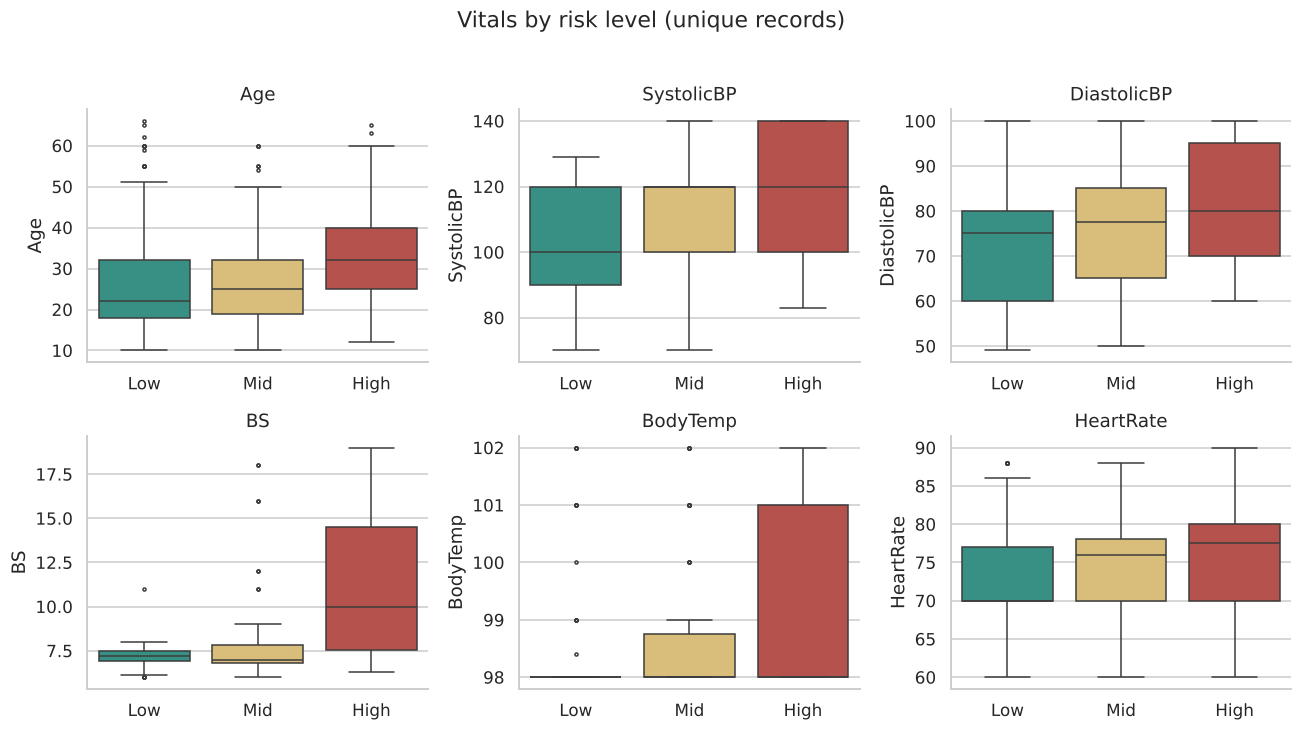

Median by class:


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
RiskLevel,,,,,,
Low,22.0,100.0,75.0,7.2,98.0,70.0
Mid,25.0,120.0,77.5,7.0,98.0,76.0
High,32.0,120.0,80.0,10.0,98.0,77.5


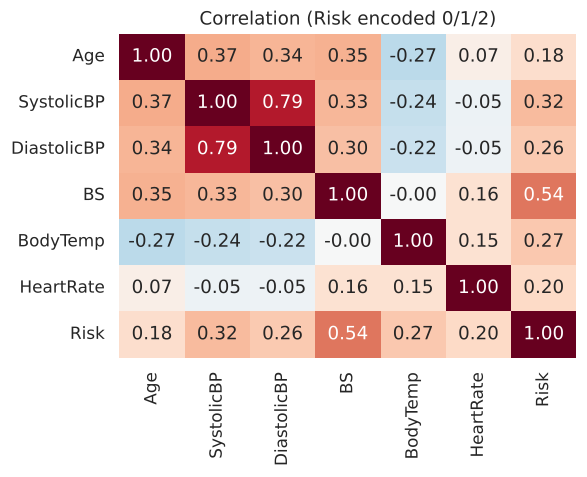

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, feat in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df, x="RiskLevel", y=feat, order=CLASSES, palette=PALETTE, ax=ax, linewidth=1, fliersize=2)
    ax.set_xlabel(""); ax.set_title(feat)
plt.suptitle("Vitals by risk level (unique records)", y=1.02)
plt.tight_layout(); plt.show()

print("Median by class:")
display(df.groupby("RiskLevel")[FEATURES].median().reindex(CLASSES))

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(df[FEATURES].assign(Risk=y).corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar=False)
plt.title("Correlation (Risk encoded 0/1/2)"); plt.tight_layout(); plt.show()

**Reading the plots.** Blood sugar and systolic blood pressure separate High from Low most clearly. Mid overlaps both neighbours on almost every feature, which foreshadows weak Mid-class results later.

## 6. Why duplicates must be removed before splitting (leakage demo)

A Random Forest can memorise training rows. If an identical record sits in both train and test, the model is rewarded for remembering rather than generalising. The cell below runs the same default forest over 10 random 80/20 splits twice: once with duplicates kept, once on unique rows only.

Accuracy, duplicates kept : 85.0% (+/- 1.5%)
Accuracy, unique rows only: 62.1% (+/- 3.9%)
Naive-split test rows with an identical twin in training: 80%


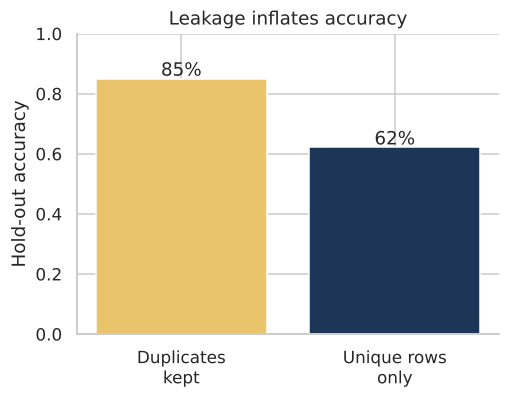

In [6]:
def default_rf():
    return RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

y_dups = clean_with_dups.RiskLevel.map(label_map).values
acc_naive, acc_unique = [], []
for s in range(10):
    a, b, c, d = train_test_split(clean_with_dups[FEATURES], y_dups, test_size=TEST_SIZE, stratify=y_dups, random_state=s)
    acc_naive.append(accuracy_score(d, default_rf().fit(a, c).predict(b)))
    a, b, c, d = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=s)
    acc_unique.append(accuracy_score(d, default_rf().fit(a, c).predict(b)))

# Share of naive-split test rows that have an exact twin in the training set.
a, b, _, _ = train_test_split(clean_with_dups, y_dups, test_size=TEST_SIZE, stratify=y_dups, random_state=SEED)
key = lambda t: t[FEATURES].astype(str).agg("|".join, axis=1)
twin_share = key(b).isin(set(key(a))).mean()

print(f"Accuracy, duplicates kept : {np.mean(acc_naive):.1%} (+/- {np.std(acc_naive):.1%})")
print(f"Accuracy, unique rows only: {np.mean(acc_unique):.1%} (+/- {np.std(acc_unique):.1%})")
print(f"Naive-split test rows with an identical twin in training: {twin_share:.0%}")

plt.figure(figsize=(4.8, 3.8))
bars = plt.bar(["Duplicates\nkept", "Unique rows\nonly"], [np.mean(acc_naive), np.mean(acc_unique)], color=["#E9C46A", "#1D3557"])
for r_ in bars: plt.text(r_.get_x() + r_.get_width() / 2, r_.get_height() + .01, f"{r_.get_height():.0%}", ha="center")
plt.ylim(0, 1); plt.ylabel("Hold-out accuracy"); plt.title("Leakage inflates accuracy"); plt.tight_layout(); plt.show()

**Takeaway.** Everything from here on uses the unique rows only. Published accuracy figures on this dataset that are far above this level are likely to include this effect.

## 7. Train/test split

A stratified 80/20 split keeps the class proportions the same in both parts. The test set is touched **once**, at the end, for the final estimate. All tuning happens inside the training set.

In [7]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
print(f"Train: {len(Xtr)}   Test: {len(Xte)}")
pd.DataFrame({"train": pd.Series(ytr).value_counts().sort_index(),
              "test": pd.Series(yte).value_counts().sort_index()}, index=[0, 1, 2]).rename(index=dict(enumerate(CLASSES)))

Train: 335   Test: 84


,train,test
Low,181,46
Mid,82,20
High,72,18


## 8. Random Forest tuning

A randomised search tries `N_SEARCH_ITER` configurations, scored by **macro-F1** with stratified 5-fold cross-validation on the training set only. Macro-F1 weights Low, Mid and High equally, so it does not let the majority class hide weak minority-class performance.

Search space: number of trees, maximum depth, minimum samples per leaf, features per split and class weighting.

In [8]:
space = {
    "n_estimators":     [200, 300, 500, 800],
    "max_depth":        [None, 4, 6, 8, 12],
    "min_samples_leaf": [1, 2, 3, 5],
    "max_features":     ["sqrt", "log2", 0.5, None],
    "class_weight":     [None, "balanced", "balanced_subsample"],
}
inner_cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
search = RandomizedSearchCV(RandomForestClassifier(random_state=SEED, n_jobs=-1), space, n_iter=N_SEARCH_ITER,
                            cv=inner_cv, scoring="f1_macro", random_state=SEED, n_jobs=-1).fit(Xtr, ytr)

best_params = search.best_params_
rf = search.best_estimator_
print("Best parameters:", best_params)
print(f"Cross-validated macro-F1 on the training set: {search.best_score_:.3f}")

Best parameters: {'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': None, 'max_depth': 12, 'class_weight': None}
Cross-validated macro-F1 on the training set: 0.683


## 9. Held-out test evaluation

The cleanest estimate of real-world performance. Key numbers for emergency triage are **High-risk recall** (how many truly High-risk women are caught) and **High-risk precision** (how many alerts are correct).

Accuracy : 0.690
Macro-F1 : 0.531

              precision    recall  f1-score   support

         Low      0.721     0.957     0.822        46
         Mid      0.333     0.050     0.087        20
        High      0.650     0.722     0.684        18

    accuracy                          0.690        84
   macro avg      0.568     0.576     0.531        84
weighted avg      0.614     0.690     0.618        84



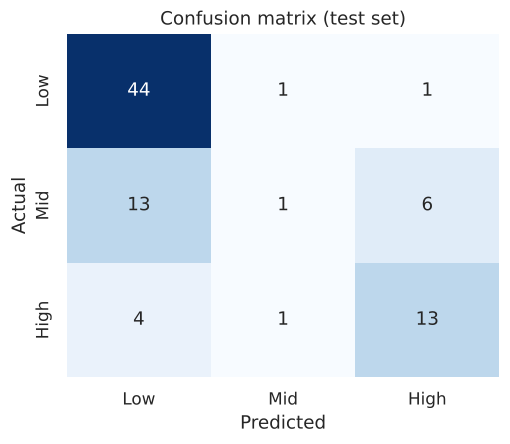

In [9]:
pred = rf.predict(Xte)
proba = rf.predict_proba(Xte)

print(f"Accuracy : {accuracy_score(yte, pred):.3f}")
print(f"Macro-F1 : {f1_score(yte, pred, average='macro'):.3f}\n")
print(classification_report(yte, pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(yte, pred)
plt.figure(figsize=(4.8, 4.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, cbar=False)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (test set)"); plt.tight_layout(); plt.show()

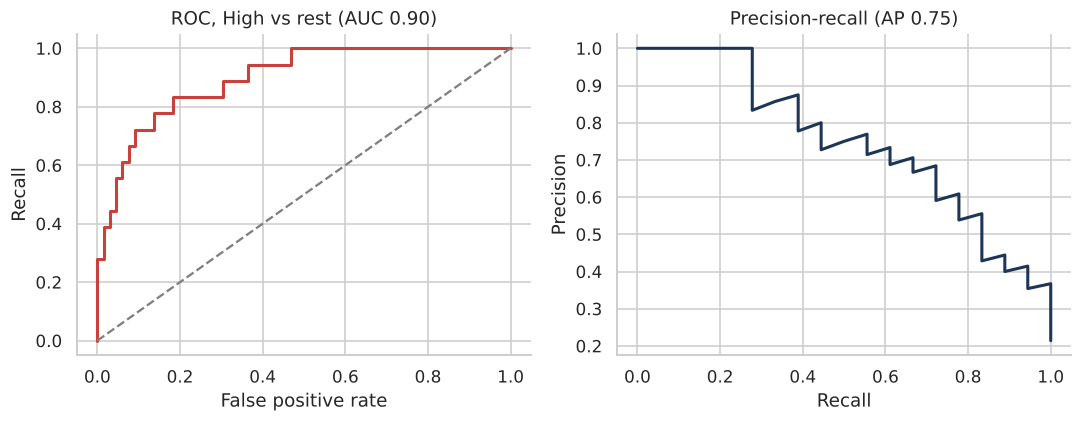

In [10]:
# High-risk versus the rest: ROC and precision-recall curves.
y_high = (yte == HIGH).astype(int)
p_high = proba[:, HIGH]
fpr, tpr, _ = roc_curve(y_high, p_high)
prec, rec, _ = precision_recall_curve(y_high, p_high)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(fpr, tpr, color="#C8423B", lw=2); ax[0].plot([0, 1], [0, 1], "--", color="grey")
ax[0].set(xlabel="False positive rate", ylabel="Recall", title=f"ROC, High vs rest (AUC {auc(fpr, tpr):.2f})")
ax[1].plot(rec, prec, color="#1D3557", lw=2)
ax[1].set(xlabel="Recall", ylabel="Precision", title=f"Precision-recall (AP {average_precision_score(y_high, p_high):.2f})")
plt.tight_layout(); plt.show()

**Reading the results.** The model is strong at the extremes (Low and High) and weak on Mid, which sits between them and overlaps both. For emergency use, treat the model as a **High-risk detector** rather than a three-way classifier. The test set contains few High-risk women, so each missed case moves recall by several points: treat the figures as indicative, not precise.

## 10. Model comparison with repeated cross-validation

Three baselines and the tuned forest are compared on identical folds (5-fold, repeated 5 times) using all unique records.

**Caveat.** The tuned forest's settings were chosen using records that also appear in these folds, so its score here is slightly optimistic. The held-out test in section 9 is the cleaner estimate.

,accuracy (mean),macro_f1 (mean),high_recall (mean),accuracy (sd),macro_f1 (sd),high_recall (sd)
model,,,,,,
Logistic regression,0.678,0.559,0.604,0.035,0.049,0.118
Decision tree,0.659,0.589,0.658,0.063,0.047,0.099
Random Forest (default),0.647,0.584,0.676,0.040,0.044,0.105
Random Forest (tuned),0.725,0.636,0.747,0.035,0.054,0.109


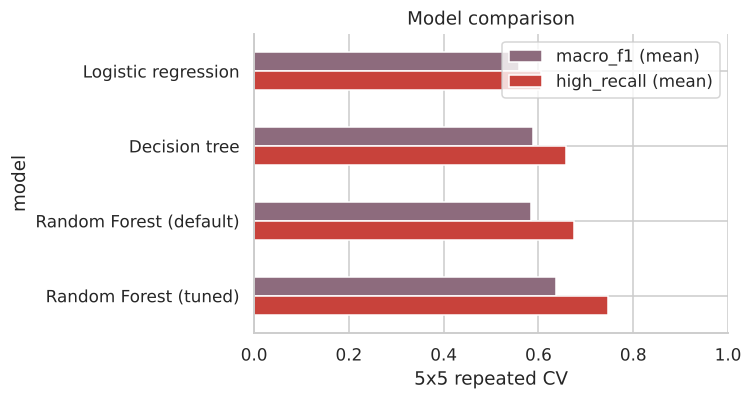

In [11]:
def high_recall(y_true, y_pred):
    return recall_score(y_true, y_pred, labels=[HIGH], average=None)[0]

scoring = {"accuracy": "accuracy", "macro_f1": "f1_macro", "high_recall": make_scorer(high_recall)}
repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)

models = {
    "Logistic regression":      make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Decision tree":            DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=SEED),
    "Random Forest (default)":  default_rf(),
    "Random Forest (tuned)":    RandomForestClassifier(**best_params, random_state=SEED, n_jobs=-1),
}
rows = []
for name, model in models.items():
    r = cross_validate(model, X, y, cv=repeated_cv, scoring=scoring, n_jobs=-1)
    rows.append({"model": name, **{f"{k} (mean)": r[f"test_{k}"].mean() for k in scoring},
                 **{f"{k} (sd)": r[f"test_{k}"].std() for k in scoring}})
comparison = pd.DataFrame(rows).set_index("model")
display(comparison.round(3))

ax = comparison[["macro_f1 (mean)", "high_recall (mean)"]].plot.barh(figsize=(7, 3.8), color=["#8D6B7D", "#C8423B"])
ax.set_xlim(0, 1); ax.set_xlabel("5x5 repeated CV"); ax.invert_yaxis(); plt.title("Model comparison"); plt.tight_layout(); plt.show()

## 11. Feature importance

Two views are shown. **Impurity importance** comes from the forest's own splits and can overstate continuous variables. **Permutation importance** shuffles one feature at a time on the held-out test set and measures the drop in macro-F1, which is a more honest check.

,impurity importance,permutation importance (macro-F1 drop)
BS,0.448,0.126
SystolicBP,0.227,0.064
Age,0.117,-0.008
BodyTemp,0.103,0.012
DiastolicBP,0.056,-0.008
HeartRate,0.049,0.000


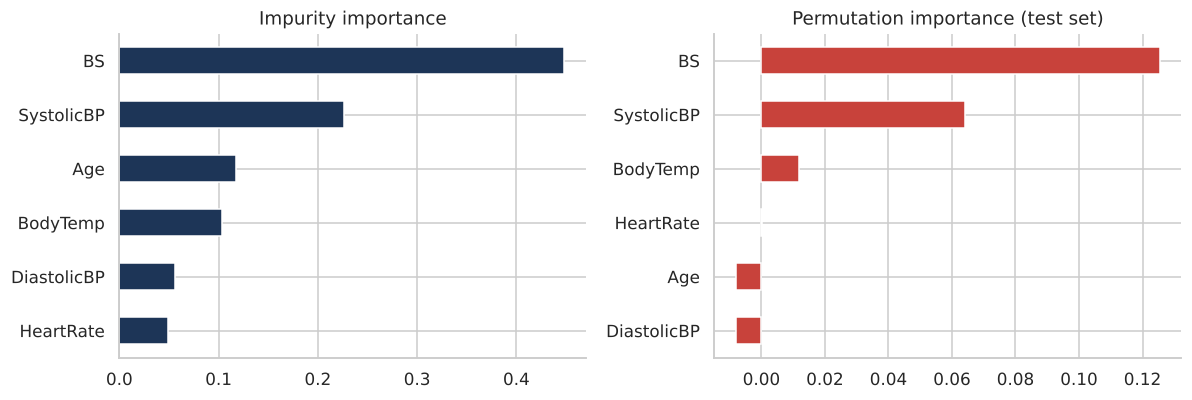

In [12]:
imp = pd.Series(rf.feature_importances_, index=FEATURES)
perm = permutation_importance(rf, Xte, yte, n_repeats=30, random_state=SEED, scoring="f1_macro")
imp_table = pd.DataFrame({"impurity importance": imp, "permutation importance (macro-F1 drop)": perm.importances_mean}) \
              .sort_values("impurity importance", ascending=False)
display(imp_table.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
imp.sort_values().plot.barh(ax=ax[0], color="#1D3557"); ax[0].set_title("Impurity importance")
pd.Series(perm.importances_mean, index=FEATURES).sort_values().plot.barh(ax=ax[1], color="#C8423B")
ax[1].set_title("Permutation importance (test set)"); plt.tight_layout(); plt.show()

**Takeaway.** Blood sugar and systolic blood pressure carry almost all of the signal. Both are cheap bedside tests (glucometer and BP cuff), which suits rural health centres.

## 12. Alert threshold for the High-risk class

The forest outputs a probability that a woman is High risk. Lowering the alert threshold catches more true High-risk women but flags more women overall (more false alarms). In emergency triage a missed case usually costs more than an extra referral, so a sensitivity-first threshold is a sensible starting point. The right value depends on referral capacity and transport cost and should be agreed with local clinicians.

,High-risk caught,recall,precision,women flagged
threshold,,,,
0.500000,12/18,67%,71%,20%
0.400000,13/18,72%,65%,24%
0.300000,13/18,72%,62%,25%
0.250000,13/18,72%,59%,26%
0.200000,14/18,78%,58%,29%
0.150000,15/18,83%,56%,32%
0.100000,15/18,83%,56%,32%


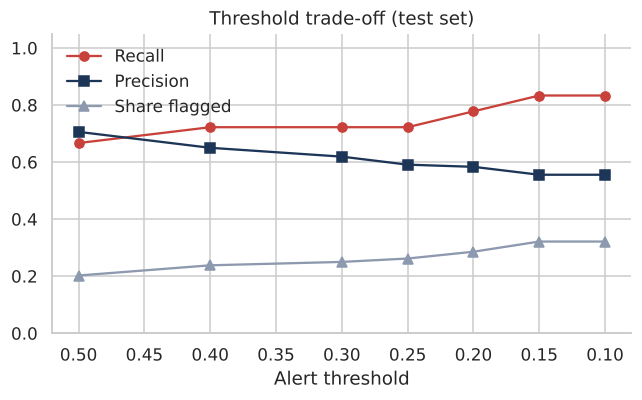

In [13]:
rows = []
for t in [0.50, 0.40, 0.30, 0.25, 0.20, 0.15, 0.10]:
    flag = (p_high >= t).astype(int)
    rows.append({"threshold": t,
                 "High-risk caught": f"{int(((flag == 1) & (y_high == 1)).sum())}/{int(y_high.sum())}",
                 "recall": recall_score(y_high, flag),
                 "precision": precision_score(y_high, flag, zero_division=0),
                 "women flagged": flag.mean()})
threshold_table = pd.DataFrame(rows).set_index("threshold")
display(threshold_table.style.format({"recall": "{:.0%}", "precision": "{:.0%}", "women flagged": "{:.0%}"}))

plt.figure(figsize=(6, 3.8))
plt.plot(threshold_table.index, threshold_table.recall, "o-", color="#C8423B", label="Recall")
plt.plot(threshold_table.index, threshold_table.precision, "s-", color="#1D3557", label="Precision")
plt.plot(threshold_table.index, threshold_table["women flagged"], "^-", color="#8D99AE", label="Share flagged")
plt.gca().invert_xaxis(); plt.xlabel("Alert threshold"); plt.ylim(0, 1.05); plt.legend(frameon=False)
plt.title("Threshold trade-off (test set)"); plt.tight_layout(); plt.show()

## 13. Save the model and a safe inference helper

The final model is retrained on **all** unique records with the selected settings, then saved with its feature order and labels. The helper `assess_pregnancy_risk` validates inputs against plausible clinical ranges before predicting, because the model has only seen a narrow range of values and handles unrealistic inputs poorly.

Danger signs (severe headache, visual disturbance, heavy bleeding, convulsions, reduced fetal movement) always mean immediate referral, whatever the model says.

In [14]:
final_model = RandomForestClassifier(**best_params, random_state=SEED, n_jobs=-1).fit(X, y)
bundle = {"model": final_model, "features": FEATURES, "labels": CLASSES, "alert_threshold": ALERT_THRESHOLD,
          "trained_rows": len(df), "data_source": source_used}
joblib.dump(bundle, "rf_pregnancy_risk.joblib")
print("Saved rf_pregnancy_risk.joblib")

# Plausible input ranges: wider than the training data on purpose, so real edge cases are not rejected,
# but impossible values (typos, unit mix-ups) are.
VALID_RANGE = {"Age": (10, 60), "SystolicBP": (60, 220), "DiastolicBP": (30, 140),
               "BS": (2.0, 30.0), "BodyTemp": (94.0, 108.0), "HeartRate": (40, 180)}

def assess_pregnancy_risk(age, systolic_bp, diastolic_bp, blood_sugar_mmol_l, body_temp_f, heart_rate,
                          bundle=bundle):
    # Return the High-risk probability and an alert flag, or raise ValueError for implausible inputs.
    values = dict(zip(FEATURES, [age, systolic_bp, diastolic_bp, blood_sugar_mmol_l, body_temp_f, heart_rate]))
    for name, v in values.items():
        lo, hi = VALID_RANGE[name]
        if not (lo <= v <= hi):
            raise ValueError(f"{name}={v} is outside the plausible range {lo}-{hi}; please re-measure or re-enter.")
    row = pd.DataFrame([values], columns=bundle["features"])
    p_high = float(bundle["model"].predict_proba(row)[0, HIGH])
    return {"p_high": round(p_high, 3), "alert": p_high >= bundle["alert_threshold"],
            "note": "Danger signs override this score: refer immediately."}

print(assess_pregnancy_risk(age=35, systolic_bp=140, diastolic_bp=90, blood_sugar_mmol_l=13, body_temp_f=98, heart_rate=70))
print(assess_pregnancy_risk(age=22, systolic_bp=100, diastolic_bp=70, blood_sugar_mmol_l=7.0, body_temp_f=98, heart_rate=72))

Saved rf_pregnancy_risk.joblib
{'p_high': 0.988, 'alert': True, 'note': 'Danger signs override this score: refer immediately.'}
{'p_high': 0.016, 'alert': False, 'note': 'Danger signs override this score: refer immediately.'}


In [15]:
# Optional: download the model when running in Colab (does nothing elsewhere).
try:
    from google.colab import files
    files.download("rf_pregnancy_risk.joblib")
except Exception:
    print("Not running in Colab; the model file is in the current folder.")

Not running in Colab; the model file is in the current folder.


## 14. Limitations and next steps

**Limitations**

- Small sample: a few hundred unique records and few High-risk cases, so uncertainty is wide.
- Single source: all data is from Bangladesh. Population, instruments and protocols differ elsewhere (including India), so performance cannot be assumed to transfer.
- Labels are risk bands assigned in the original study, not confirmed clinical outcomes.
- Mid risk is not separable from these six vitals.
- Missing predictors that clinicians use: gestational age, obstetric history, urine protein, haemoglobin, symptoms.
- No prospective or clinical validation.

**Next steps**

1. Re-run on the original UCI file (`DATA_SOURCE="uci"`) and compare with the fallback copy.
2. Validate on Indian primary health centre data, ideally with confirmed outcomes.
3. Add richer inputs and test whether Mid risk becomes separable.
4. Calibrate probabilities and add per-prediction explanations (SHAP).
5. Compare gradient boosting on larger data.
6. Pilot offline in a mobile app with clinician review and outcome logging.

**References**

- Ahmed, M. (2020). *Maternal Health Risk* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5DP5D (CC BY 4.0).